# Introducere în Data Mining




---

## Partea 1 — Statistici descriptive

O **serie** este o colecție unidimensională de valori. În primul exemplu, `speed` este o listă Python care reprezintă zece observații numerice. Valorile sunt ilustrative; nu este specificată o unitate de măsură sau o sursă din lumea reală.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from pathlib import Path

RANDOM_SEED = 42

speed = [33, 66, 99, 132, 61, 53, 80, 49, 139, 80]

print("Număr de observații:", len(speed))
print("Observații:", speed)

Număr de observații: 10
Observații: [33, 66, 99, 132, 61, 53, 80, 49, 139, 80]


### 1. Media aritmetică

**Media aritmetică** este suma tuturor observațiilor împărțită la numărul acestora. Folosește fiecare valoare, astfel că valorile neobișnuit de mari sau de mici o pot influența semnificativ.

Formula:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i
$$

unde \(n\) este numărul observațiilor, iar \(x_i\) reprezintă fiecare observație.

In [ ]:
mean_value = np.mean(speed)
print("Media aritmetică:", mean_value)

Media aritmetică: 79.2


**Experiment:** Adaugă într-o listă nouă o copie a celei mai mari valori înmulțită cu zece și compară media acestei liste cu media inițială. Nu suprascrie lista originală `speed`; păstrează comparația reproductibilă.

In [ ]:
# Experiment opțional: compară media inițială cu media afectată de o valoare extremă.
speed_with_extreme_value = speed + [max(speed) * 10]
print("Media inițială:", np.mean(speed))
print("Media după adăugarea unei valori extreme:", np.mean(speed_with_extreme_value))

Media inițială: 79.2
Media după adăugarea unei valori extreme: 198.36363636363637


### 2. Mediana

**Mediana** este valoarea din mijloc după sortarea observațiilor. Dacă numărul valorilor este par, mediana este media aritmetică a celor două valori centrale. În general, mediana este mai puțin sensibilă la valorile extreme decât media.

In [ ]:
median_value = np.median(speed)
print("Mediana:", median_value)

Mediana: 73.0


### 3. Mode

**Mode** este valoarea care apare cel mai frecvent. Un set de date poate avea un singur mod, mai multe moduri sau nicio valoare repetată. În acest exemplu, `80` apare de două ori, iar toate celelalte valori apar o singură dată.

`scipy.stats.mode` returnează atât mode, cât și frecvența sa. Argumentul `keepdims=True` păstrează valorile returnate în tablouri, ceea ce face indexarea explicită și compatibilă cu versiunile actuale SciPy.

In [ ]:
mode_result = stats.mode(speed, keepdims=True)
mode_value = mode_result.mode[0]
mode_count = mode_result.count[0]
print("Mode:", mode_value)
print("Frecvența mode-ului:", mode_count)

Mode: 80
Frecvența mode-ului: 2


### 4. Varianța

**Varianța** măsoară cât de răspândite sunt valorile în jurul mediei. Pentru a calcula varianța, scade media din fiecare observație, ridică diferențele la pătrat și calculează media lor:

$$
\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2
$$

În mod implicit, `np.var()` folosește formula și împarte la `n`.

#### Exemplu pas cu pas: calculul manual al varianței

Considerăm următoarele șapte valori: **32, 111, 138, 28, 59, 77, 97**. În acest exemplu calculăm **varianța**, deci la final împărțim suma pătratelor diferențelor la numărul total de valori, `n = 7`.

**Pasul 1 — Calculăm media aritmetică.** Adunăm toate valorile și împărțim suma la numărul lor:

$$
\bar{x} = \frac{32+111+138+28+59+77+97}{7} = \frac{542}{7} \approx 77.4
$$

**Pasul 2 — Scădem media din fiecare valoare.** Diferențele arată cât de departe este fiecare observație de media calculată:

```text
 32 - 77.4 = -45.4
111 - 77.4 =  33.6
138 - 77.4 =  60.6
 28 - 77.4 = -49.4
 59 - 77.4 = -18.4
 77 - 77.4 =  -0.4
 97 - 77.4 =  19.6
```

**Pasul 3 — Ridicăm fiecare diferență la pătrat.** Pătratul elimină semnul diferenței, astfel încât abaterile pozitive și negative să nu se anuleze reciproc:

```text
(-45.4)² = 2061.16
 (33.6)² = 1128.96
 (60.6)² = 3672.36
(-49.4)² = 2440.36
(-18.4)² =  338.56
 (-0.4)² =    0.16
 (19.6)² =  384.16
```

**Pasul 4 — Calculăm media pătratelor diferențelor.** Adunăm pătratele și împărțim la `7`:

$$
\sigma^2 = \frac{2061.16+1128.96+3672.36+2440.36+338.56+0.16+384.16}{7}
$$

$$
\sigma^2 = \frac{10025.72}{7} \approx 1432.2
$$

Prin urmare, **varianța este aproximativ `1432.2`**. În pașii intermediari s-a folosit media rotunjită la `77.4`; folosind media exactă, rezultatul rotunjit la o zecimală este tot `1432.2`.

> **Atenție:** pentru varianța unui eșantion se împarte la `n - 1 = 6`, nu la `n = 7`. În exemplul de mai sus calculăm varianța.

In [ ]:
speed_variance = np.var(speed)
print("Varianța:", speed_variance)

Varianța: 1099.56


### 5. Abaterea standard

**Abaterea standard** este rădăcina pătrată a varianței. Descrie dispersia folosind aceeași unitate de măsură ca observațiile inițiale, ceea ce o face adesea mai ușor de interpretat decât varianța.

In [ ]:
speed_std = np.std(speed)
print("Abaterea standard:", speed_std)

Abaterea standard: 33.15961399051563


### 6. Percentile

O **percentilă** indică o poziție în distribuție: percentila 25 este o valoare sub care se află aproximativ 25% dintre observații, conform metodei folosite pentru calcul. Percentila 50 este mediana.

Metoda implicită din NumPy interpolează între observații atunci când este necesar. Pentru acest set de date, compară percentilele 25, 50 și 75.

In [ ]:
p25, p50, p75 = np.percentile(speed, [25, 50, 75])
print("Percentila 25:", p25)
print("Percentila 50 (mediana):", p50)
print("Percentila 75:", p75)

Percentila 25: 55.0
Percentila 50 (mediana): 73.0
Percentila 75: 94.25


### Compararea statisticilor descriptive

Tabelul de mai jos reunește principalele statistici. Folosește-l pentru a compara măsurile tendinței centrale (media, mediana, moda) și măsurile dispersiei (varianța și abaterea standard). Varianța este exprimată în unități pătrate, în timp ce abaterea standard este exprimată în unitățile originale.

In [ ]:
summary = pd.DataFrame({
    "Statistică": ["Media", "Mediana", "Moda", "Varianța", "Abaterea standard", "Percentila 25", "Percentila 50", "Percentila 75"],
    "Valoare": [mean_value, median_value, mode_value, speed_variance, speed_std, p25, p50, p75],
})
display(summary)

,Statistică,Valoare
0,Media,79.200000
1,Mediana,73.000000
2,Moda,80.000000
3,Varianța,1099.560000
4,Abaterea standard,33.159614
5,Percentila 25,55.000000
6,Percentila 50,73.000000
7,Percentila 75,94.250000


---

## Partea 2 — Generarea și vizualizarea unei distribuții

O **distribuție uniformă** pe un interval atribuie aceeași densitate de probabilitate valorilor din acel interval. Celula de mai jos generează 250 de numere pseudoaleatoare între 0 și 5.

O sămânță aleatoare fixă face ca secvența generată să poată fi reprodusă în același mediu. Valoarea `42` este o convenție, nu un număr special din punct de vedere matematic.

In [ ]:
rng = np.random.default_rng(RANDOM_SEED)
uniform_data = rng.uniform(low=0.0, high=5.0, size=250)

print("Număr de valori generate:", len(uniform_data))
print("Minim:", uniform_data.min())
print("Maxim:", uniform_data.max())
print("Media:", uniform_data.mean())

Număr de valori generate: 250
Minim: 0.03681134875502756
Maxim: 4.961877820279185
Media: 2.480384761027855


### 7. Histogramă

O **histogramă** grupează valorile numerice în intervale numite clase (*bins*). Înălțimea fiecărei bare arată câte observații se află în intervalul respectiv. O histogramă este utilă pentru explorarea formei, dispersiei și eventualei asimetrii a unei distribuții, deși aspectul ei depinde de numărul și lățimea claselor.

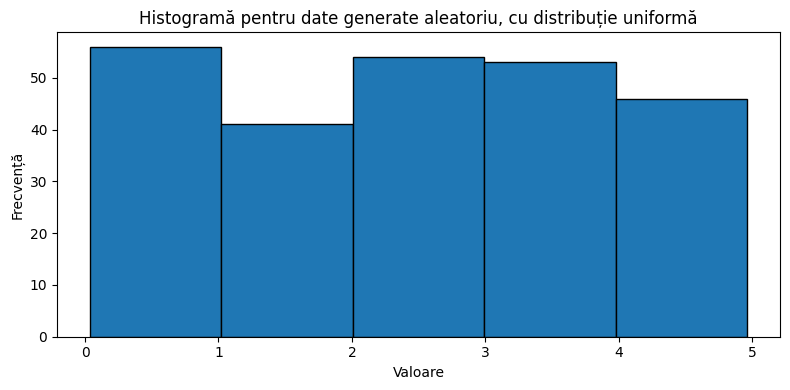

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(uniform_data, bins=5, edgecolor="black")
plt.title("Histogramă pentru date generate aleatoriu, cu distribuție uniformă")
plt.xlabel("Valoare")
plt.ylabel("Frecvență")
plt.tight_layout()
plt.show()

**Experiment:** Modifică `bins=5` în `bins=10` și execută din nou celula histogramei. Ce se schimbă în reprezentare? Modificarea numărului de clase schimbă datele de bază?

---

## Partea 3 — Diagrame de dispersie

O **diagramă de dispersie** reprezintă observații pereche pentru două variabile numerice. Fiecare punct reprezintă o pereche de valori. O diagramă de dispersie poate evidenția relații, grupuri, tendințe sau observații neobișnuite, dar o asociere vizuală nu demonstrează, de una singură, o relație de cauzalitate.

Următorul exemplu folosește `speed` și o a doua listă, `y_values`. Aceste valori sunt perechi ilustrative create pentru reprezentare grafică; nu au o semnificație documentată în lumea reală.

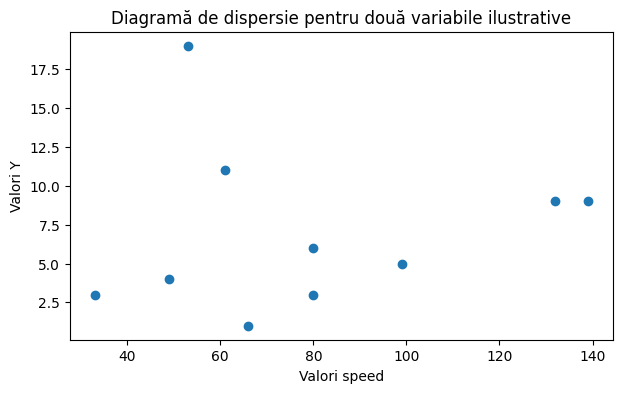

In [ ]:
y_values = [3, 1, 5, 9, 11, 19, 6, 4, 9, 3]

plt.figure(figsize=(7, 4))
plt.scatter(speed, y_values)
plt.title("Diagramă de dispersie pentru două variabile ilustrative")
plt.xlabel("Valori speed")
plt.ylabel("Valori Y")
plt.show()

**Experiment:** Descrie dacă graficul sugerează o relație pozitivă clară, o relație negativă sau lipsa unui tipar liniar evident.

---

## Partea 4 — Încărcarea și explorarea unui set de date CSV

Fișierul `Dataset.csv` conține un set de date ilustrativ, de dimensiuni mici, cu patru coloane:

- `Țară`: variabilă categorială;
- `Vârstă`: variabilă numerică, cu o valoare lipsă;
- `Salariu`: variabilă numerică, cu o valoare lipsă;
- `Achiziționat`: rezultat categorial (`Da` sau `Nu`).

### 8. Deschiderea fișierului

`pandas.read_csv()` citește un fișier CSV într-un `DataFrame`. Calea fișierului este relativă la directorul de lucru curent al notebook-ului. Dacă fișierul nu este găsit, verifică dacă `Dataset.csv` a fost încărcat sau plasat lângă notebook.

In [ ]:
dataset = pd.read_csv("Dataset.csv")

display(dataset.head())

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes


### 9. Inspectarea structurii și a tipurilor de date

Înainte de a analiza un set de date, verifică numărul de rânduri și coloane, numele coloanelor, tipurile de date și numărul valorilor care nu lipsesc. Acest lucru ajută la identificarea unor probleme precum text neașteptat în coloanele numerice sau valori lipsă.

In [ ]:
print("Dimensiunea setului de date (rânduri, coloane):", dataset.shape)
print("Numele coloanelor:", dataset.columns.tolist())
dataset.info()

Dimensiunea setului de date (rânduri, coloane): (10, 4)
Numele coloanelor: ['Country', 'Age', 'Salary', 'Purchased']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Country    10 non-null     object 
 1   Age        9 non-null      float64
 2   Salary     9 non-null      float64
 3   Purchased  10 non-null     object 
dtypes: float64(2), object(2)
memory usage: 452.0+ bytes


### 10. Statistici descriptive pentru toate coloanele

`DataFrame.describe()` rezumă implicit coloanele numerice. Cu `include="all"`, pandas include și coloanele categoriale: de exemplu, numărul valorilor unice, valoarea cea mai frecventă și frecvența acesteia. Unele statistici nu au sens pentru toate tipurile de date, astfel că pandas afișează `NaN` atunci când o statistică nu se aplică.

In [ ]:
display(dataset.describe(include="all"))

### 12. Vizualizarea vârstei și a salariului

O diagramă de dispersie poate arăta cum variază împreună două variabile numerice. În acest grafic sunt reprezentate variabilele `Vârstă` și `Salariu`.

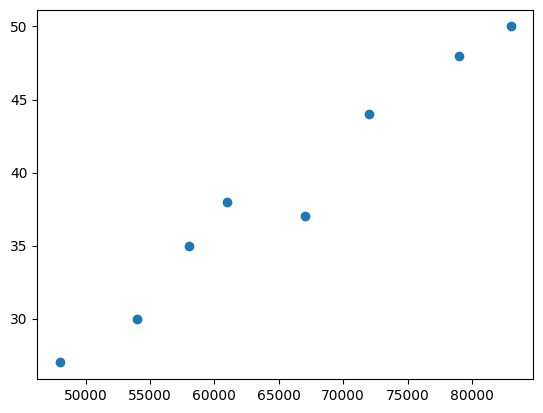

In [ ]:
plt.scatter(dataset['Salary'], dataset['Age'])
plt.show()